In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

In [ ]:
!git clone https://github.com/sajjadrezvani/SigPep-LB2.git

fatal: destination path 'SigPep-LB2' already exists and is not an empty directory.


In [ ]:
DATA_DIR = Path("SigPep-LB2/data/prepration")

print(DATA_DIR)
print(DATA_DIR.exists())

SigPep-LB2/data/prepration
True


In [ ]:
files = sorted(DATA_DIR.glob("*"))

for file in files:
    print(file.name)

negative_benchmark.fasta
negative_benchmark.tsv
negative_train.fasta
negative_train.tsv
negative_train_5fold.tsv
positive_benchmark.fasta
positive_benchmark.tsv
positive_train.fasta
positive_train.tsv
positive_train_5fold.tsv
training_5fold_cv_master.tsv


In [ ]:
!head $DATA_DIR/training_5fold_cv_master.tsv



Q12396	accession	Label	Set	CV_Fold	O74740	organism	kingdom	protein_length	cleavage_position	tm_helix_first_90
O35310	O35310	1	Training	0		Mus musculus	Metazoa	311	20.0	
P08887	P08887	1	Training	1		Homo sapiens	Metazoa	468	19.0	
P0C1X6	P0C1X6	1	Training	2		Tityus discrepans	Metazoa	62	26.0	
Q8VCS0	Q8VCS0	1	Training	3		Mus musculus	Metazoa	530	22.0	
Q9TY95	Q9TY95	1	Training	4		Plasmodium falciparum (isolate 3D7)	Other	997	22.0	
O02380	O02380	1	Training	0		Tyrophagus putrescentiae	Metazoa	141	15.0	
P49259	P49259	1	Training	1		Bos taurus	Metazoa	1463	20.0	
Q9Z0M9	Q9Z0M9	1	Training	2		Mus musculus	Metazoa	193	28.0	
P09791	P09791	1	Training	3		Trypanosoma brucei brucei	Other	129	27.0	


In [ ]:
!head $DATA_DIR/positive_train_5fold.tsv



Q12396	accession	Label	Set	CV_Fold	organism	kingdom	protein_length	cleavage_position	tm_helix_first_90
O35310	O35310	1	Training	0	Mus musculus	Metazoa	311	20.0	
P08887	P08887	1	Training	1	Homo sapiens	Metazoa	468	19.0	
P0C1X6	P0C1X6	1	Training	2	Tityus discrepans	Metazoa	62	26.0	
Q8VCS0	Q8VCS0	1	Training	3	Mus musculus	Metazoa	530	22.0	
Q9TY95	Q9TY95	1	Training	4	Plasmodium falciparum (isolate 3D7)	Other	997	22.0	
O02380	O02380	1	Training	0	Tyrophagus putrescentiae	Metazoa	141	15.0	
P49259	P49259	1	Training	1	Bos taurus	Metazoa	1463	20.0	
Q9Z0M9	Q9Z0M9	1	Training	2	Mus musculus	Metazoa	193	28.0	
P09791	P09791	1	Training	3	Trypanosoma brucei brucei	Other	129	27.0	


In [ ]:
!wc -l $DATA_DIR/training_5fold_cv_master.tsv

7865 SigPep-LB2/data/prepration/training_5fold_cv_master.tsv


In [ ]:
!wc -l $DATA_DIR/positive_train_5fold.tsv


849 SigPep-LB2/data/prepration/positive_train_5fold.tsv


In [ ]:
master_path = DATA_DIR / "training_5fold_cv_master.tsv"

master = pd.read_csv(master_path, sep="\t")

master.head()

,Q12396,accession,Label,Set,CV_Fold,O74740,organism,kingdom,protein_length,cleavage_position,tm_helix_first_90
0,O35310,O35310,1,Training,0,NaN,Mus musculus,Metazoa,311,20.0,NaN
1,P08887,P08887,1,Training,1,NaN,Homo sapiens,Metazoa,468,19.0,NaN
2,P0C1X6,P0C1X6,1,Training,2,NaN,Tityus discrepans,Metazoa,62,26.0,NaN
3,Q8VCS0,Q8VCS0,1,Training,3,NaN,Mus musculus,Metazoa,530,22.0,NaN
4,Q9TY95,Q9TY95,1,Training,4,NaN,Plasmodium falciparum (isolate 3D7),Other,997,22.0,NaN


In [ ]:
master = master.drop(columns=['Q12396','O74740'])
master.to_csv("training_5fold_cv_master.tsv", sep="\t", index=False)
master.head()


,accession,Label,Set,CV_Fold,organism,kingdom,protein_length,cleavage_position,tm_helix_first_90
0,O35310,1,Training,0,Mus musculus,Metazoa,311,20.0,NaN
1,P08887,1,Training,1,Homo sapiens,Metazoa,468,19.0,NaN
2,P0C1X6,1,Training,2,Tityus discrepans,Metazoa,62,26.0,NaN
3,Q8VCS0,1,Training,3,Mus musculus,Metazoa,530,22.0,NaN
4,Q9TY95,1,Training,4,Plasmodium falciparum (isolate 3D7),Other,997,22.0,NaN


In [ ]:
master.shape

(7864, 9)

In [ ]:
master.dtypes

,0
accession,object
Label,int64
Set,object
CV_Fold,int64
organism,object
kingdom,object
protein_length,int64
cleavage_position,float64
tm_helix_first_90,object


In [ ]:
master.isna().sum()

,0
accession,0
Label,0
Set,0
CV_Fold,0
organism,0
kingdom,0
protein_length,0
cleavage_position,7016
tm_helix_first_90,848


In [ ]:
master['Label'].value_counts()

,count
Label,
0,7016
1,848


In [ ]:
master["CV_Fold"].value_counts().sort_index()

,count
CV_Fold,
0,1574
1,1573
2,1573
3,1572
4,1572


In [ ]:
print(
    pd.crosstab(
        master["CV_Fold"],
        master["Label"]
    )
)

Label       0    1
CV_Fold           
0        1404  170
1        1403  170
2        1403  170
3        1403  169
4        1403  169


In [ ]:
def read_fasta(path):
    sequences = {}
    current_id = None
    current_seq = []

    with open(path) as f:
        for line in f:
            line = line.strip()

            if line.startswith(">"):
                if current_id is not None:
                    sequences[current_id] = "".join(current_seq)

                current_id = line[1:].split()[0]
                current_seq = []
            else:
                current_seq.append(line)

        if current_id is not None:
            sequences[current_id] = "".join(current_seq)

    return sequences


positive_seqs = read_fasta(DATA_DIR / "positive_train.fasta")
negative_seqs = read_fasta(DATA_DIR / "negative_train.fasta")

print("Positive:", len(positive_seqs))
print("Negative:", len(negative_seqs))
list(positive_seqs.items())[:5]

Positive: 848
Negative: 7016


[('sp|P13612|ITA4_HUMAN',
  'MAWEARREPGPRRAAVRETVMLLLCLGVPTGRPYNVDTESALLYQGPHNTLFGYSVVLHSHGANRWLLVGAPTANWLANASVINPGAIYRCRIGKNPGQTCEQLQLGSPNGEPCGKTCLEERDNQWLGVTLSRQPGENGSIVTCGHRWKNIFYIKNENKLPTGGCYGVPPDLRTELSKRIAPCYQDYVKKFGENFASCQAGISSFYTKDLIVMGAPGSSYWTGSLFVYNITTNKYKAFLDKQNQVKFGSYLGYSVGAGHFRSQHTTEVVGGAPQHEQIGKAYIFSIDEKELNILHEMKGKKLGSYFGASVCAVDLNADGFSDLLVGAPMQSTIREEGRVFVYINSGSGAVMNAMETNLVGSDKYAARFGESIVNLGDIDNDGFEDVAIGAPQEDDLQGAIYIYNGRADGISSTFSQRIEGLQISKSLSMFGQSISGQIDADNNGYVDVAVGAFRSDSAVLLRTRPVVIVDASLSHPESVNRTKFDCVENGWPSVCIDLTLCFSYKGKEVPGYIVLFYNMSLDVNRKAESPPRFYFSSNGTSDVITGSIQVSSREANCRTHQAFMRKDVRDILTPIQIEAAYHLGPHVISKRSTEEFPPLQPILQQKKEKDIMKKTINFARFCAHENCSADLQVSAKIGFLKPHENKTYLAVGSMKTLMLNVSLFNAGDDAYETTLHVKLPVGLYFIKILELEEKQINCEVTDNSGVVQLDCSIGYIYVDHLSRIDISFLLDVSSLSRAEEDLSITVHATCENEEEMDNLKHSRVTVAIPLKYEVKLTVHGFVNPTSFVYGSNDENEPETCMVEKMNLTFHVINTGNSMAPNVSVEIMVPNSFSPQTDKLFNILDVQTTTGECHFENYQRVCALEQQKSAMQTLKGIVRFLSKTDKRLLYCIKADPHCLNFLCNFGKMESGKEASVHIQLEGRPSILEMDETSALKFEIRATGFPEPNPRVIELNKDENVAHVLLEGLHHQR

In [ ]:
positive_lengths = [len(seq) for seq in positive_seqs.values()]
negative_lengths = [len(seq) for seq in negative_seqs.values()]

print("Positive:")
print(pd.Series(positive_lengths).describe())

print("\nNegative:")
print(pd.Series(negative_lengths).describe())

Positive:
count     848.000000
mean      397.488208
std       414.361562
min        46.000000
25%       147.750000
50%       282.000000
75%       500.000000
max      3396.000000
dtype: float64

Negative:
count     7016.000000
mean       580.506129
std        612.914156
min         40.000000
25%        273.000000
50%        431.000000
75%        701.000000
max      18562.000000
dtype: float64


In [ ]:
for accession, sequence in list(positive_seqs.items())[:5]:
    print(accession, len(sequence), sequence[:30])

sp|P13612|ITA4_HUMAN 1032 MAWEARREPGPRRAAVRETVMLLLCLGVPT
sp|P02763|A1AG1_HUMAN 201 MALSWVLTVLSLLPLLEAQIPLCANLVPVP
sp|P15018|LIF_HUMAN 202 MKVLAAGVVPLLLVLHWKHGAGSPLPITPV
sp|Q9NPR2|SEM4B_HUMAN 837 MLRTAMGLRSWLAAPWGALPPRPPLLLLLL
sp|D4A540|AUGN_RAT 148 MGTSSARPAVLALAGLALLLLLCLGPGDVS


In [ ]:
fasta_accessions = [
    fasta_id.split("|")[1]
    for fasta_id in positive_seqs
]

In [ ]:
tsv_accessions = set(master["accession"])

fasta_accessions = set(
    fasta_id.split("|")[1]
    for fasta_id in positive_seqs
)


In [ ]:
negative_accessions = set(
    fasta_id.split("|")[1]
    for fasta_id in negative_seqs
)


In [ ]:
print("Master:", len(tsv_accessions))
print("Positive FASTA:", len(fasta_accessions))
print("Negative FASTA:", len(negative_accessions))

Master: 7864
Positive FASTA: 848
Negative FASTA: 7016


In [ ]:
positive_meta = master[master["Label"] == 1].copy()

print("Positive proteins:", len(positive_meta))
positive_meta[["accession", "cleavage_position"]].head()

Positive proteins: 848


,accession,cleavage_position
0,O35310,20.0
1,P08887,19.0
2,P0C1X6,26.0
3,Q8VCS0,22.0
4,Q9TY95,22.0


In [ ]:
cleavage_dict = dict(
    zip(
        positive_meta["accession"],
        positive_meta["cleavage_position"]
    )
)

list(cleavage_dict.items())[:5]

[('O35310', 20.0),
 ('P08887', 19.0),
 ('P0C1X6', 26.0),
 ('Q8VCS0', 22.0),
 ('Q9TY95', 22.0)]

In [ ]:
positive_meta["cleavage_position"].min()

14.0

In [ ]:
contexts = {}

for fasta_id, sequence in positive_seqs.items():
    accession = fasta_id.split("|")[1]

    if accession not in cleavage_dict:
        continue

    cleavage = int(cleavage_dict[accession])

    start = cleavage - 13
    end = cleavage + 2

    context = sequence[start:end]

    if len(context) == 15:
        contexts[accession] = context

print("Valid contexts:", len(contexts))

Valid contexts: 848


In [ ]:
for accession, context in list(contexts.items())[:10]:
    print(accession, context)

P13612 MLLLCLGVPTGRPYN
P02763 VLTVLSLLPLLEAQI
P15018 PLLLVLHWKHGAGSP
Q9NPR2 LLLLLQPPPPTWALS
D4A540 LLLLCLGPGDVSGNK
Q01965 PLLFLLMGLGASGKE
O35310 AVLLVAQPQLVHSHP
Q9VA83 LALFACLGSLALAKD
Q02862 FFIFACLVVVALAKH
Q9C9H5 LLFSSLLISNGDANP


In [ ]:
from collections import Counter

print(Counter(len(context) for context in contexts.values()))

Counter({15: 848})


In [ ]:
amino_acids = list("ACDEFGHIKLMNPQRSTVWY")
positions = list(range(-13, 3))
positions.remove(0)

print(amino_acids)
print(positions)

['A', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'P', 'Q', 'R', 'S', 'T', 'V', 'W', 'Y']
[-13, -12, -11, -10, -9, -8, -7, -6, -5, -4, -3, -2, -1, 1, 2]


In [ ]:
counts = pd.DataFrame(
    1,
    index=amino_acids,
    columns=positions
)
mycounts = counts.copy()
counts

,-13,-12,-11,-10,-9,-8,-7,-6,-5,-4,-3,-2,-1,1,2
A,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
C,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
D,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
E,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
F,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
G,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
H,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
I,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
K,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
L,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1


In [ ]:
contexts.values()
for i in range(15):
  for amino in contexts.values():
    if i >= 13:
      counts.loc[amino[i], i-12]+=1
    else:
      counts.loc[amino[i], i-13]+=1

counts


,-13,-12,-11,-10,-9,-8,-7,-6,-5,-4,-3,-2,-1,1,2
A,103,102,86,87,154,145,107,138,143,91,221,79,419,133,40
C,29,26,25,32,33,54,38,33,19,22,54,13,33,19,17
D,5,1,1,2,7,8,4,13,14,19,4,36,5,56,60
E,3,2,2,4,6,7,10,12,27,29,5,69,6,75,81
F,79,73,46,73,53,50,63,50,15,27,6,23,5,31,20
G,27,17,27,33,35,37,43,31,100,89,82,33,162,61,54
H,5,4,4,3,6,5,12,9,32,13,2,40,2,23,22
I,49,63,71,54,38,32,41,61,15,24,37,21,3,27,30
K,2,2,1,3,1,3,6,3,14,19,6,22,6,33,34
L,322,366,349,367,325,258,293,178,61,133,34,119,12,81,32


In [ ]:
print("Total residues:", counts.sum().sum())
print("Expected:", len(contexts) * 15)
counts.sum(axis=0) , counts.sum(axis=1)

Total residues: 13020
Expected: 12720


(-13    868
 -12    868
 -11    868
 -10    868
 -9     868
 -8     868
 -7     868
 -6     868
 -5     868
 -4     868
 -3     868
 -2     868
 -1     868
  1     868
  2     868
 dtype: int64,
 A    2048
 C     447
 D     235
 E     338
 F     614
 G     831
 H     182
 I     566
 K     155
 L    2930
 M     230
 N     160
 P     524
 Q     348
 R     252
 S    1078
 T     565
 V    1151
 W     194
 Y     172
 dtype: int64)

In [ ]:
N = len(contexts)
print(N)
pspm = counts/(N+20)
pspm


848


,-13,-12,-11,-10,-9,-8,-7,-6,-5,-4,-3,-2,-1,1,2
A,0.118664,0.117512,0.099078,0.100230,0.177419,0.167051,0.123272,0.158986,0.164747,0.104839,0.254608,0.091014,0.482719,0.153226,0.046083
C,0.033410,0.029954,0.028802,0.036866,0.038018,0.062212,0.043779,0.038018,0.021889,0.025346,0.062212,0.014977,0.038018,0.021889,0.019585
D,0.005760,0.001152,0.001152,0.002304,0.008065,0.009217,0.004608,0.014977,0.016129,0.021889,0.004608,0.041475,0.005760,0.064516,0.069124
E,0.003456,0.002304,0.002304,0.004608,0.006912,0.008065,0.011521,0.013825,0.031106,0.033410,0.005760,0.079493,0.006912,0.086406,0.093318
F,0.091014,0.084101,0.052995,0.084101,0.061060,0.057604,0.072581,0.057604,0.017281,0.031106,0.006912,0.026498,0.005760,0.035714,0.023041
G,0.031106,0.019585,0.031106,0.038018,0.040323,0.042627,0.049539,0.035714,0.115207,0.102535,0.094470,0.038018,0.186636,0.070276,0.062212
H,0.005760,0.004608,0.004608,0.003456,0.006912,0.005760,0.013825,0.010369,0.036866,0.014977,0.002304,0.046083,0.002304,0.026498,0.025346
I,0.056452,0.072581,0.081797,0.062212,0.043779,0.036866,0.047235,0.070276,0.017281,0.027650,0.042627,0.024194,0.003456,0.031106,0.034562
K,0.002304,0.002304,0.001152,0.003456,0.001152,0.003456,0.006912,0.003456,0.016129,0.021889,0.006912,0.025346,0.006912,0.038018,0.039171
L,0.370968,0.421659,0.402074,0.422811,0.374424,0.297235,0.337558,0.205069,0.070276,0.153226,0.039171,0.137097,0.013825,0.093318,0.036866


In [ ]:
print(pspm.sum(axis=0))


-13    1.0
-12    1.0
-11    1.0
-10    1.0
-9     1.0
-8     1.0
-7     1.0
-6     1.0
-5     1.0
-4     1.0
-3     1.0
-2     1.0
-1     1.0
 1     1.0
 2     1.0
dtype: float64


In [ ]:
print("Minimum:", pspm.min().min())
print("Maximum:", pspm.max().max())

Minimum: 0.001152073732718894
Maximum: 0.4827188940092166


In [ ]:
swissProt_distro = {"L":0.0972, "A":0.0875, "S":0.0730, "G":0.0707, "V":0.0678, "E":0.0634, "R":0.0590, "T":0.0559, "D":0.0548, "P":0.0526, "I":0.0514, "K":0.0501, "Q":0.0395, "N":0.0379, "F":0.0378, "Y":0.0279, "H":0.0233, "M":0.0227, "C":0.0146, "W":0.0128}

In [ ]:
background = pd.Series(swissProt_distro)
background = background.reindex(amino_acids)
background

,0
A,0.0875
C,0.0146
D,0.0548
E,0.0634
F,0.0378
G,0.0707
H,0.0233
I,0.0514
K,0.0501
L,0.0972


In [ ]:
background.sum()

np.float64(0.9999)

In [ ]:
distro_normal = pspm.div(background, axis=0)
distro_normal

,-13,-12,-11,-10,-9,-8,-7,-6,-5,-4,-3,-2,-1,1,2
A,1.356155,1.342989,1.132324,1.145490,2.027650,1.909151,1.408822,1.816985,1.882818,1.198157,2.909809,1.040158,5.516787,1.751152,0.526662
C,2.288366,2.051638,1.972729,2.525093,2.604002,4.261095,2.998548,2.604002,1.499274,1.736002,4.261095,1.025819,2.604002,1.499274,1.341456
D,0.105116,0.021023,0.021023,0.042046,0.147163,0.168186,0.084093,0.273302,0.294325,0.399442,0.084093,0.756837,0.105116,1.177302,1.261395
E,0.054515,0.036343,0.036343,0.072686,0.109029,0.127201,0.181715,0.218058,0.490631,0.526974,0.090858,1.253834,0.109029,1.362863,1.471892
F,2.407773,2.224904,1.401994,2.224904,1.615341,1.523907,1.920123,1.523907,0.457172,0.822910,0.182869,0.700997,0.152391,0.944822,0.609563
G,0.439972,0.277019,0.439972,0.537743,0.570334,0.602924,0.700695,0.505153,1.629524,1.450277,1.336210,0.537743,2.639829,0.994010,0.879943
H,0.247226,0.197781,0.197781,0.148336,0.296671,0.247226,0.593343,0.445007,1.582247,0.642788,0.098890,1.977809,0.098890,1.137240,1.087795
I,1.098280,1.412075,1.591386,1.210350,0.851728,0.717244,0.918969,1.367247,0.336208,0.537933,0.829314,0.470692,0.067242,0.605175,0.672417
K,0.045991,0.045991,0.022995,0.068986,0.022995,0.068986,0.137973,0.068986,0.321937,0.436914,0.137973,0.505901,0.137973,0.758851,0.781846
L,3.816541,4.338055,4.136561,4.349908,3.852098,3.057973,3.472815,2.109765,0.723009,1.576397,0.402989,1.410461,0.142231,0.960061,0.379284


In [ ]:
pswm = np.log(distro_normal)
pswm

,-13,-12,-11,-10,-9,-8,-7,-6,-5,-4,-3,-2,-1,1,2
A,0.304654,0.294898,0.124272,0.135833,0.706877,0.646659,0.342754,0.597178,0.632769,0.180784,1.068087,0.039373,1.707796,0.560274,-0.641196
C,0.827838,0.718639,0.679418,0.926278,0.957050,1.449526,1.098128,0.957050,0.404981,0.551584,1.449526,0.025491,0.957050,0.404981,0.293755
D,-2.252689,-3.862127,-3.862127,-3.168979,-1.916216,-1.782685,-2.475832,-1.297177,-1.223069,-0.917688,-2.475832,-0.278608,-2.252689,0.163225,0.232218
E,-2.909288,-3.314753,-3.314753,-2.621606,-2.216141,-2.061990,-1.705315,-1.522994,-0.712063,-0.640604,-2.398462,0.226206,-2.216141,0.309588,0.386549
F,0.878702,0.799714,0.337896,0.799714,0.479546,0.421277,0.652389,0.421277,-0.782695,-0.194909,-1.698986,-0.355251,-1.881308,-0.056758,-0.495013
G,-0.821045,-1.283669,-0.821045,-0.620374,-0.561534,-0.505964,-0.355682,-0.682895,0.488288,0.371754,0.289837,-0.620374,0.970714,-0.006008,-0.127898
H,-1.397452,-1.620595,-1.620595,-1.908278,-1.215130,-1.397452,-0.521983,-0.809665,0.458846,-0.441940,-2.313743,0.681990,-2.313743,0.128604,0.084153
I,0.093746,0.345060,0.464605,0.190909,-0.160488,-0.332339,-0.084503,0.312799,-1.090024,-0.620021,-0.187157,-0.753552,-2.699462,-0.502238,-0.396877
K,-3.079310,-3.079310,-3.772457,-2.673845,-3.772457,-2.673845,-1.980698,-2.673845,-1.133400,-0.828018,-1.980698,-0.681415,-1.980698,-0.275950,-0.246097
L,1.339344,1.467426,1.419865,1.470155,1.348618,1.117752,1.244965,0.746576,-0.324333,0.455142,-0.908847,0.343916,-1.950300,-0.040758,-0.969471


In [ ]:
pswm[-1].sort_values(ascending=False)

,-1
A,1.707796
G,0.970714
C,0.957050
S,0.578492
P,-0.324645
T,-0.480803
Q,-1.232152
R,-1.371025
Y,-1.800769
F,-1.881308


In [ ]:
print("Shape:", pswm.shape)
print("Min:", pswm.min().min())
print("Max:", pswm.max().max())

Shape: (20, 15)
Min: -3.9359738795839325
Max: 1.707795690880356


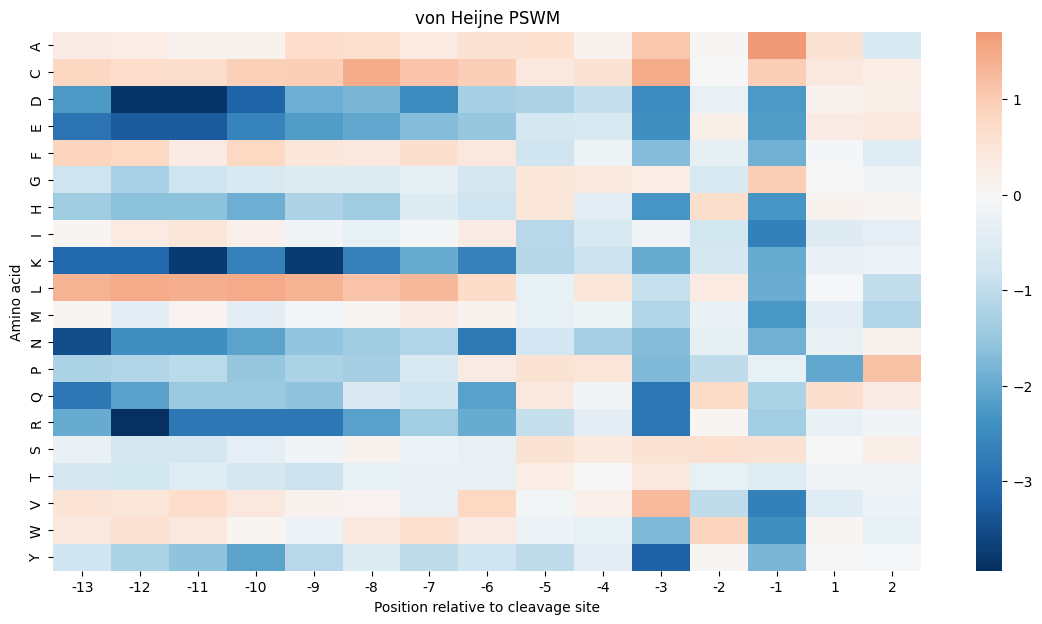

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 7))

sns.heatmap(
    pswm,
    center=0,
    cmap="RdBu_r",
    xticklabels=pswm.columns,
    yticklabels=pswm.index
)

plt.xlabel("Position relative to cleavage site")
plt.ylabel("Amino acid")
plt.title("von Heijne PSWM")
plt.show()

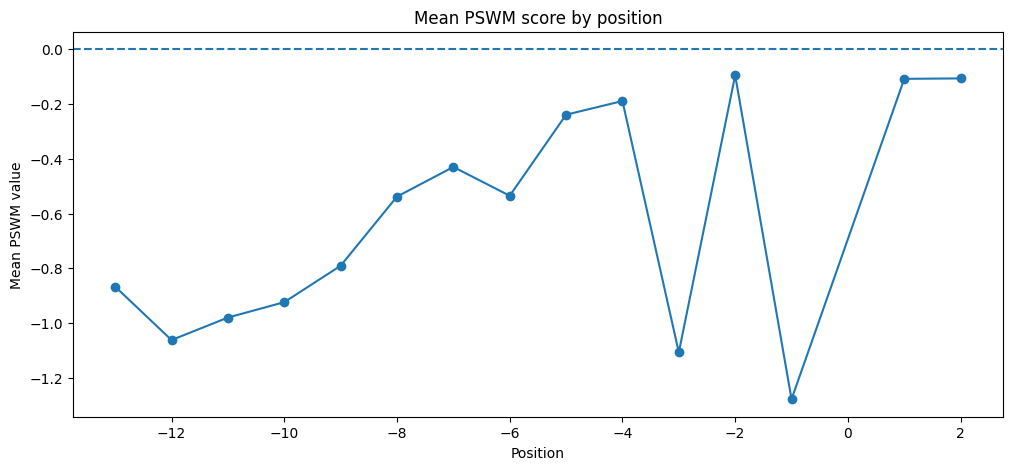

In [ ]:
plt.figure(figsize=(12, 5))

pswm.mean(axis=0).plot(marker="o")

plt.axhline(0, linestyle="--")
plt.xlabel("Position")
plt.ylabel("Mean PSWM value")
plt.title("Mean PSWM score by position")
plt.show()

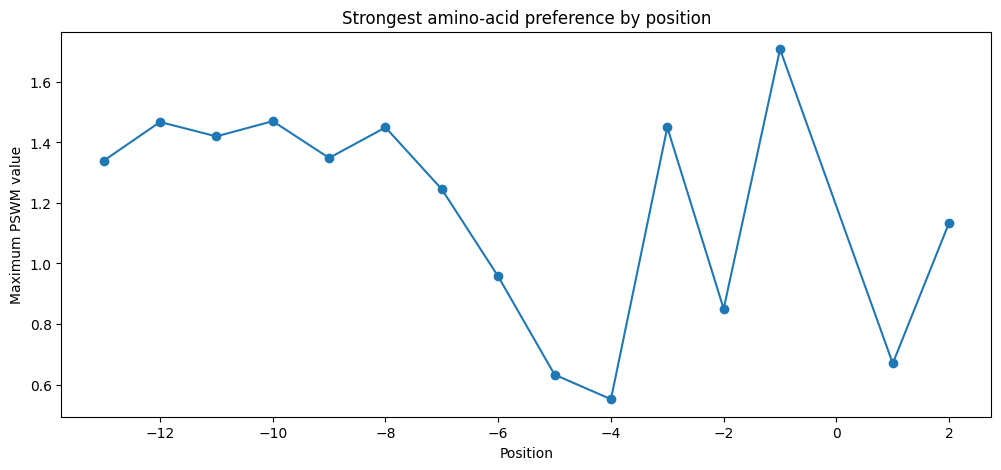

In [ ]:
plt.figure(figsize=(12, 5))

pswm.max(axis=0).plot(marker="o")

plt.xlabel("Position")
plt.ylabel("Maximum PSWM value")
plt.title("Strongest amino-acid preference by position")
plt.show()

In [ ]:
import plotly.graph_objects as go

fig = go.Figure(
    data=[
        go.Surface(
            x=pswm.columns,
            y=list(range(20)),
            z=pswm.values,
            surfacecolor=pswm.values,
            colorscale="Hot",
            colorbar=dict(title="PSWM")
        )
    ]
)

fig.update_layout(
    title="von Heijne PSWM",
    scene=dict(
        xaxis_title="Position",
        yaxis_title="Amino acid",
        zaxis_title="PSWM score",
        yaxis=dict(
            tickmode="array",
            tickvals=list(range(20)),
            ticktext=amino_acids
        )
    ),
    width=900,
    height=600
)

fig.show()

In [ ]:
def score_sequence(sequence, pswm, window_size=15, maximum_length=90):
    # N-terminus extraction
    n_term = sequence[:maximum_length]
    # if the length is less that 15 aa, we do not go through it
    if len(n_term) < window_size:
        return -np.inf

    max_score = -np.inf


    for i in range(len(n_term) - window_size + 1):
        window = n_term[i : i + window_size]

        # claculating the score of windows
        window_score = 0.0
        for col_idx, aa in enumerate(window):
            # check if the desired aa is here
            if aa in pswm.index:
                window_score += pswm.iloc[:, col_idx][aa]
            else:
                window_score += 0.0

        # confirming max score
        if window_score > max_score:
            max_score = window_score

    return max_score

In [ ]:
# Merge positive and negative FASTA dicts, keyed by the UniProt accession only
sequences = {
    fasta_id.split("|")[1]: seq
    for fasta_id, seq in {**positive_seqs, **negative_seqs}.items()
}

master["sequence"] = master["accession"].map(sequences)

print("Sequences found:", master["sequence"].notna().sum(), "/", len(master))
master

Sequences found: 7864 / 7864


,accession,Label,Set,CV_Fold,organism,kingdom,protein_length,cleavage_position,tm_helix_first_90,sequence
0,O35310,1,Training,0,Mus musculus,Metazoa,311,20.0,NaN,MTLLLLGAVLLVAQPQLVHSHPAAPGPGLKQQELLRKVIILPEDTG...
1,P08887,1,Training,1,Homo sapiens,Metazoa,468,19.0,NaN,MLAVGCALLAALLAAPGAALAPRRCPAQEVARGVLTSLPGDSVTLT...
2,P0C1X6,1,Training,2,Tityus discrepans,Metazoa,62,26.0,NaN,MHFSGVAFILISMVLIGSIFETTVEAGEGPKSDCKPDLCEAACKDL...
3,Q8VCS0,1,Training,3,Mus musculus,Metazoa,530,22.0,NaN,MKAWGALWIVLGLLLWPEPGAASSLPLLMDSIIQALAELEQKVPVT...
4,Q9TY95,1,Training,4,Plasmodium falciparum (isolate 3D7),Other,997,22.0,NaN,MKSYISLFFILCVIFNKNVIKCTGESQTGNTGGGQAGNTGGDQAGS...
...,...,...,...,...,...,...,...,...,...,...
7859,Q587E3,0,Training,1,Trypanosoma brucei brucei (strain 927/4 GUTat1...,Other,735,NaN,False,MYPRHDDVSLFQRFVNDHKLEEKGLPLYQLAQLEGTDQVMLGVDGT...
7860,P93306,0,Training,2,Arabidopsis thaliana,Plants,394,NaN,False,MTTRKRQIKNFTLNFGPQHPAAHGVLRLVLEMNGEVVERAEPHIGL...
7861,Q04964,0,Training,3,Saccharomyces cerevisiae (strain ATCC 204508 /...,Fungi,104,NaN,False,MQNSQDYFYAQNRCQQQQAPSTLRTVTMAEFRRVPLPPMAEVPMLS...
7862,Q17604,0,Training,4,Caenorhabditis elegans,Metazoa,161,NaN,False,MVSHKKNDRPRPLWILKIHKRLSLFEFKRYATGIGKDDGQDISWVL...


In [ ]:
#Roxy
def extract_context(sequence, cleavage_position):
    """Return the 15-residue window [-13, +2] around the cleavage site, or None."""
    c = int(cleavage_position)
    if c - 13 < 0:
        return None
    ctx = sequence[c - 13 : c + 2]
    return ctx if len(ctx) == 15 else None


def build_pswm(train_df, background):
    """Build the PSWM from the positive proteins in train_df."""
    pos_df = train_df[train_df["Label"] == 1]

    contexts = [
        extract_context(seq, cl)
        for seq, cl in zip(pos_df["sequence"], pos_df["cleavage_position"])
    ]
    contexts = [c for c in contexts if c is not None]

    # pseudocounts: every cell starts at 1
    counts = pd.DataFrame(1, index=amino_acids, columns=positions)
    for ctx in contexts:
        for col_idx, aa in enumerate(ctx):
            counts.iloc[amino_acids.index(aa), col_idx] += 1

    pspm = counts / (len(contexts) + 20)          # PSPM
    pswm = np.log(pspm.div(background, axis=0))   # log-odds vs SwissProt
    return pswm, len(contexts)

In [ ]:
#Roxy
check_pswm, n_ctx = build_pswm(master, background)

print("Contexts used:", n_ctx)
print("Identical to your pswm:", np.allclose(check_pswm.values, pswm.values))
check_pswm

Contexts used: 848
Identical to your pswm: True


,-13,-12,-11,-10,-9,-8,-7,-6,-5,-4,-3,-2,-1,1,2
A,0.304654,0.294898,0.124272,0.135833,0.706877,0.646659,0.342754,0.597178,0.632769,0.180784,1.068087,0.039373,1.707796,0.560274,-0.641196
C,0.827838,0.718639,0.679418,0.926278,0.957050,1.449526,1.098128,0.957050,0.404981,0.551584,1.449526,0.025491,0.957050,0.404981,0.293755
D,-2.252689,-3.862127,-3.862127,-3.168979,-1.916216,-1.782685,-2.475832,-1.297177,-1.223069,-0.917688,-2.475832,-0.278608,-2.252689,0.163225,0.232218
E,-2.909288,-3.314753,-3.314753,-2.621606,-2.216141,-2.061990,-1.705315,-1.522994,-0.712063,-0.640604,-2.398462,0.226206,-2.216141,0.309588,0.386549
F,0.878702,0.799714,0.337896,0.799714,0.479546,0.421277,0.652389,0.421277,-0.782695,-0.194909,-1.698986,-0.355251,-1.881308,-0.056758,-0.495013
G,-0.821045,-1.283669,-0.821045,-0.620374,-0.561534,-0.505964,-0.355682,-0.682895,0.488288,0.371754,0.289837,-0.620374,0.970714,-0.006008,-0.127898
H,-1.397452,-1.620595,-1.620595,-1.908278,-1.215130,-1.397452,-0.521983,-0.809665,0.458846,-0.441940,-2.313743,0.681990,-2.313743,0.128604,0.084153
I,0.093746,0.345060,0.464605,0.190909,-0.160488,-0.332339,-0.084503,0.312799,-1.090024,-0.620021,-0.187157,-0.753552,-2.699462,-0.502238,-0.396877
K,-3.079310,-3.079310,-3.772457,-2.673845,-3.772457,-2.673845,-1.980698,-2.673845,-1.133400,-0.828018,-1.980698,-0.681415,-1.980698,-0.275950,-0.246097
L,1.339344,1.467426,1.419865,1.470155,1.348618,1.117752,1.244965,0.746576,-0.324333,0.455142,-0.908847,0.343916,-1.950300,-0.040758,-0.969471


In [ ]:
#Roxy


import matplotlib.pyplot as plt
import numpy as np
aa_index = {aa: i for i, aa in enumerate(amino_acids)}

def score_sequence_fast(sequence, pswm_array, window_size=15, maximum_length=90):
    n_term = sequence[:maximum_length]
    if len(n_term) < window_size:
        return -np.inf

    idx = np.array([aa_index.get(a, -1) for a in n_term])   # -1 = non-standard residue
    n_windows = len(n_term) - window_size + 1
    scores = np.zeros(n_windows)

    for col in range(window_size):
        col_idx = idx[col : col + n_windows]
        valid = (col_idx >= 0)
        scores += np.where(valid, pswm_array[np.clip(col_idx, 0, None), col], 0.0)

    # # 1. Create or insert your NumPy array
    # # (Replacing this with your actual array, e.g., scores)
    # y_values = scores
    # x_values = col_idx  # Creates [0, 1, 2, 3...] for the X axis

    # plt.figure(figsize=(10, 5))  # Sets width and height
    # plt.bar(x_values, y_values, color='royalblue', edgecolor='black', alpha=0.85, width=0.6)


    # # 3. Add styling and labels
    # plt.title("Sequence Scores by Amino Acid Residue (Bar Chart)", fontsize=14, fontweight='bold')
    # plt.xlabel("Amino Acid Position", fontsize=12)
    # plt.ylabel("Score", fontsize=12)
    # plt.grid(axis='y', linestyle='--', alpha=0.5)  # Grid lines only across the Y-axis

    # # 4. Rotate labels to prevent text overlapping
    # plt.xticks(rotation=45, ha='right')

    # # 5. Clean up margins and display
    # plt.tight_layout()
    # plt.show()




    return scores.max()

In [ ]:
# #Roxy
pswm_array = pswm.values

for seq in master["sequence"].head(20):
    assert abs(score_sequence(seq, pswm) - score_sequence_fast(seq, pswm_array)) < 1e-9

print(" scoring agreed")

 scoring agreed


In [ ]:
# #Roxy
# import matplotlib.pyplot as plt

# master["full_score"] = [score_sequence_fast(s, pswm_array) for s in master["sequence"]]

# plt.figure(figsize=(9, 4))
# plt.hist(master.loc[master.Label == 0, "full_score"], bins=50, alpha=0.6, density=True, label="No SP")
# plt.hist(master.loc[master.Label == 1, "full_score"], bins=50, alpha=0.6, density=True, label="SP")
# plt.xlabel("Global SP score (max over windows)")
# plt.ylabel("Density")
# plt.legend()
# plt.title("Score distribution (exploratory, NOT an evaluation)")
# plt.show()

In [ ]:
def window_scores(sequence, pswm_array, window_size=15, maximum_length=90):
    """Return the N-terminal region and the PSWM score of every sliding window."""
    n_term = sequence[:maximum_length]
    idx = np.array([aa_index.get(a, -1) for a in n_term])
    n_win = len(n_term) - window_size + 1
    scores = np.zeros(n_win)
    for col in range(window_size):
        col_idx = idx[col : col + n_win]
        scores += np.where(col_idx >= 0, pswm_array[np.clip(col_idx, 0, None), col], 0.0)
    return n_term, scores

In [ ]:
import matplotlib.pyplot as plt

def plot_score_profile(sequence, pswm, title=None, cleavage_position=None,
                       theta=None, window_size=15, maximum_length=90):
    n_term, scores = window_scores(sequence, pswm.values, window_size, maximum_length)
    n_win = len(scores)
    best = int(np.argmax(scores))

    colors = ["#2c3e50"] * n_win
    colors[best] = "#7b1c2b"

    fig, ax = plt.subplots(figsize=(11, 4.5))
    ax.bar(range(n_win), scores, color=colors, width=0.7)
    ax.axhline(0, color="lightgray", lw=1)

    # optional: decision threshold
    if theta is not None:
        ax.axhline(theta, color="#e08a00", ls="--", lw=1.2, label=f"threshold θ = {theta:.2f}")
        ax.legend(loc="upper right", frameon=False)

    # optional: window of the annotated cleavage site
    if cleavage_position is not None:
        true_start = int(cleavage_position) - 13
        if 0 <= true_start < n_win:
            ax.axvline(true_start, color="#7b1c2b", ls=":", lw=1)
            ax.text(true_start, ax.get_ylim()[0], " annotated\n cleavage window",
                    color="#7b1c2b", fontsize=8, va="bottom")

    # label the maximum
    ax.annotate(f"max = {scores[best]:.1f}\n{n_term[best:best + window_size]}",
                xy=(best, scores[best]),
                xytext=(best, scores[best] + 0.12 * (scores.max() - scores.min() + 1)),
                ha="center", color="#7b1c2b", fontweight="bold", fontsize=9,
                arrowprops=dict(arrowstyle="->", color="#7b1c2b"))

    # x-axis: window sequences for short inputs, positions for long ones
    if n_win <= 20:
        ax.set_xticks(range(n_win))
        ax.set_xticklabels([n_term[i:i + window_size] for i in range(n_win)],
                           rotation=90, fontsize=7, family="monospace")
    else:
        ax.set_xticks(range(0, n_win, 5))
        ax.set_xticklabels([str(i + 1) for i in range(0, n_win, 5)])

    ax.set_xlabel("Window start position (N-terminus = 1)")
    ax.set_ylabel("PSWM score")
    ax.set_title(title or "Scanning the sequence: the score profile", pad=20)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.margins(y=0.3)
    plt.tight_layout()
    return fig

accession                                                       O35310
Label                                                                1
Set                                                           Training
CV_Fold                                                              0
organism                                                  Mus musculus
kingdom                                                        Metazoa
protein_length                                                     311
cleavage_position                                                 20.0
tm_helix_first_90                                                  NaN
sequence             MTLLLLGAVLLVAQPQLVHSHPAAPGPGLKQQELLRKVIILPEDTG...
Name: 0, dtype: object MTLLLLGAVLLVAQPQLVHS


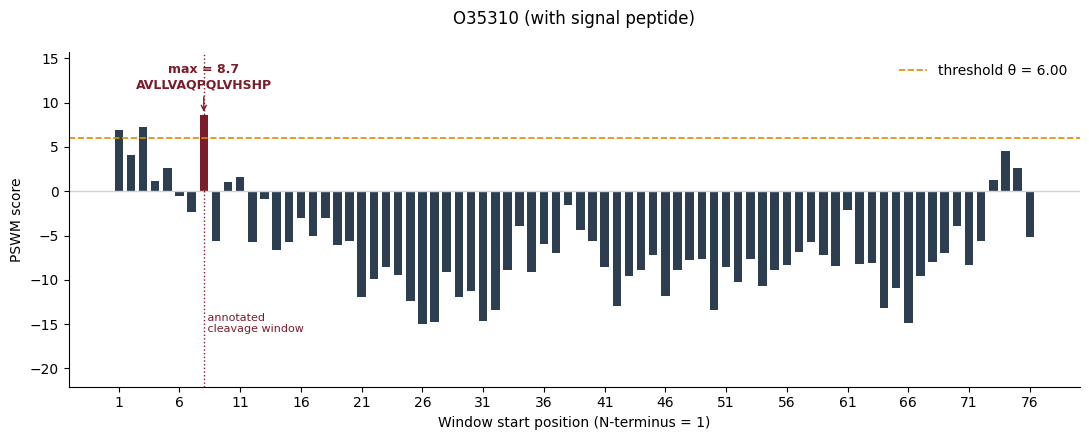

accession                                                       P08887
Label                                                                1
Set                                                           Training
CV_Fold                                                              1
organism                                                  Homo sapiens
kingdom                                                        Metazoa
protein_length                                                     468
cleavage_position                                                 19.0
tm_helix_first_90                                                  NaN
sequence             MLAVGCALLAALLAAPGAALAPRRCPAQEVARGVLTSLPGDSVTLT...
Name: 1, dtype: object MLAVGCALLAALLAAPGAA


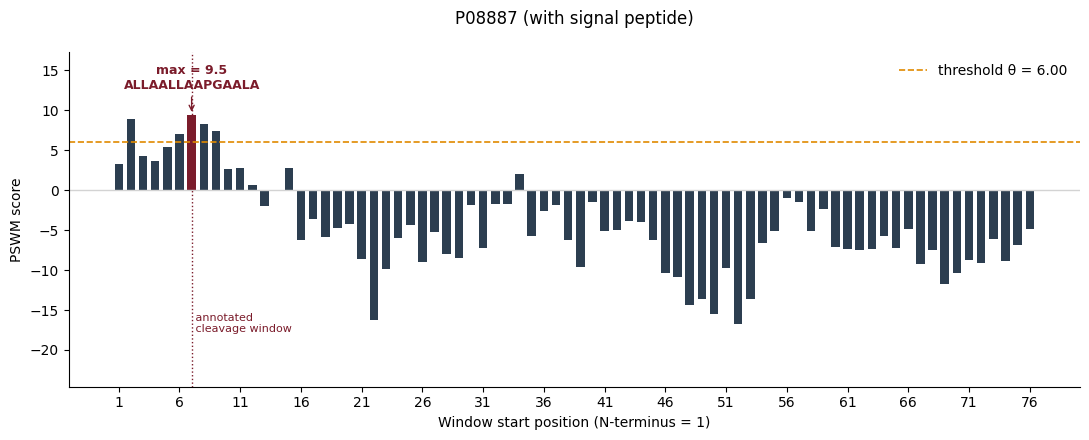

accession                                                       P0C1X6
Label                                                                1
Set                                                           Training
CV_Fold                                                              2
organism                                             Tityus discrepans
kingdom                                                        Metazoa
protein_length                                                      62
cleavage_position                                                 26.0
tm_helix_first_90                                                  NaN
sequence             MHFSGVAFILISMVLIGSIFETTVEAGEGPKSDCKPDLCEAACKDL...
Name: 2, dtype: object MHFSGVAFILISMVLIGSIFETTVEA


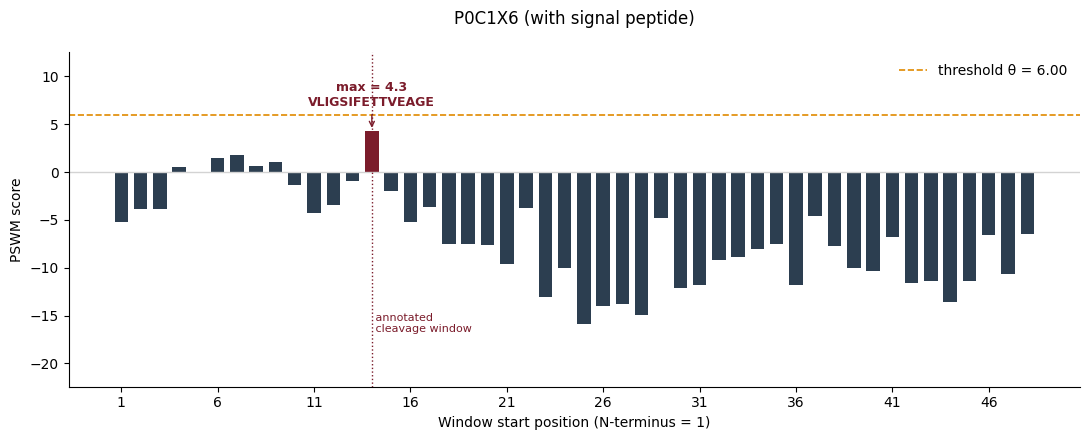

accession                                                       Q8VCS0
Label                                                                1
Set                                                           Training
CV_Fold                                                              3
organism                                                  Mus musculus
kingdom                                                        Metazoa
protein_length                                                     530
cleavage_position                                                 22.0
tm_helix_first_90                                                  NaN
sequence             MKAWGALWIVLGLLLWPEPGAASSLPLLMDSIIQALAELEQKVPVT...
Name: 3, dtype: object MKAWGALWIVLGLLLWPEPGAA


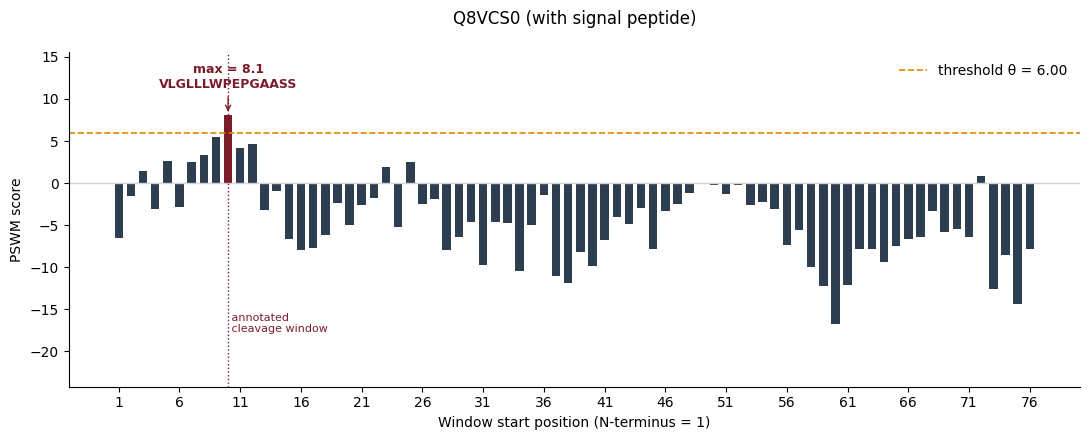

accession                                                       Q9TY95
Label                                                                1
Set                                                           Training
CV_Fold                                                              4
organism                           Plasmodium falciparum (isolate 3D7)
kingdom                                                          Other
protein_length                                                     997
cleavage_position                                                 22.0
tm_helix_first_90                                                  NaN
sequence             MKSYISLFFILCVIFNKNVIKCTGESQTGNTGGGQAGNTGGDQAGS...
Name: 4, dtype: object MKSYISLFFILCVIFNKNVIKC


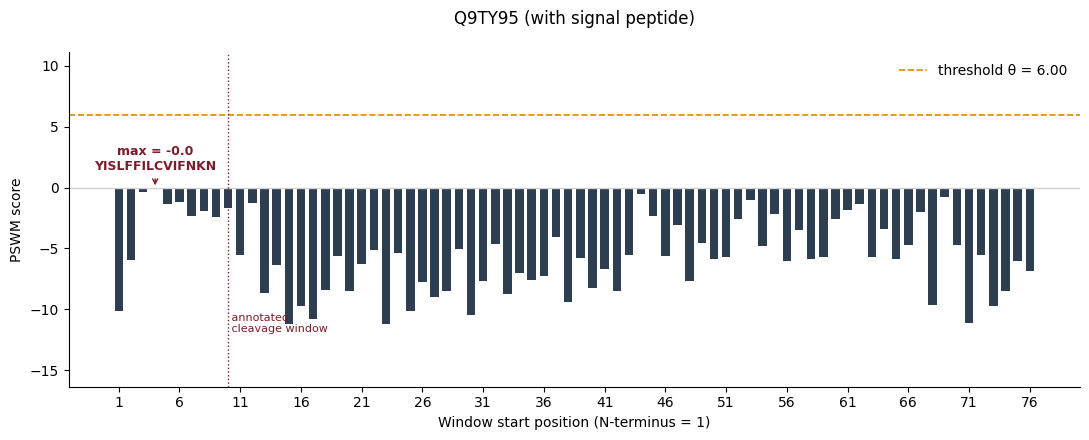

In [ ]:
for i in range(5):
  row = master[master["Label"] == 1].iloc[i]
  print(row, row["sequence"][:int(row["cleavage_position"])] )

  fig = plot_score_profile(
      row["sequence"], pswm,
      title=f"{row['accession']} (with signal peptide)",
      cleavage_position=row["cleavage_position"],
      theta=6.0,   # or use a θ from your results table
  )
  plt.show()



In [ ]:
def make_splits(j):
    test = j
    val = (j + 1) % 5
    train = [(i + j) % 5 for i in range(2, 5)]
    return train, val, test

for j in range(5):
    print(f"Run {j+1}: test={make_splits(j)[2]}, val={make_splits(j)[1]}, train={make_splits(j)[0]}")

Run 1: test=0, val=1, train=[2, 3, 4]
Run 2: test=1, val=2, train=[3, 4, 0]
Run 3: test=2, val=3, train=[4, 0, 1]
Run 4: test=3, val=4, train=[0, 1, 2]
Run 5: test=4, val=0, train=[1, 2, 3]


In [ ]:
from sklearn.metrics import precision_recall_curve

def best_threshold(y_true, scores):
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    f1 = np.divide(2 * precision * recall, precision + recall,
                   out=np.zeros_like(precision), where=(precision + recall) > 0)
    return thresholds[np.argmax(f1[:-1])]

In [ ]:
from sklearn.metrics import (precision_score, recall_score, accuracy_score,
                             matthews_corrcoef, f1_score)

def compute_metrics(y_true, y_pred):
    return {
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall":    recall_score(y_true, y_pred),
        "Accuracy":  accuracy_score(y_true, y_pred),
        "MCC":       matthews_corrcoef(y_true, y_pred),
        "F1":        f1_score(y_true, y_pred),
    }

In [ ]:
train_folds = [2, 3, 4]
master["CV_Fold"].isin(train_folds)

,CV_Fold
0,False
1,False
2,True
3,True
4,True
...,...
7859,False
7860,True
7861,True
7862,True


In [ ]:
#test

results = []
j = 0

train_folds, val_fold, test_fold = make_splits(j)

train_df = master[master["CV_Fold"].isin(train_folds)]
val_df   = master[master["CV_Fold"] == val_fold]
test_df  = master[master["CV_Fold"] == test_fold]


# 1. PSWM from training folds only
pswm_cv, n_pos = build_pswm(train_df, background)
arr = pswm_cv.values

print(n_pos)
# 2. Threshold from the validation set
val_scores = np.array([score_sequence_fast(s, arr) for s in val_df["sequence"]])
print(val_scores)

theta = best_threshold(val_df["Label"].values, val_scores)

# 3. Classify the test set
test_scores = np.array([score_sequence_fast(s, arr) for s in test_df["sequence"]])
y_pred = (test_scores >= theta).astype(int)

# 4. Metrics on the test fold
m = compute_metrics(test_df["Label"].values, y_pred)
m.update({"Run": j + 1, "Test": test_fold, "Val": val_fold,
          "Train": train_folds, "Threshold": theta, "N_pos_train": n_pos})
results.append(m)

print(f"Run {j+1} done | θ = {theta:.3f} | MCC = {m['MCC']:.3f}")

results_df = pd.DataFrame(results)
results_df.round(3)

508
[ 9.6687069  11.2367719   3.55932081 ...  4.7603237  -0.37846166
 -1.18791341]
Run 1 done | θ = 5.621 | MCC = 0.699


,Precision,Recall,Accuracy,MCC,F1,Run,Test,Val,Train,Threshold,N_pos_train
0,0.668,0.806,0.936,0.699,0.731,1,0,1,"[2, 3, 4]",5.621,508


In [ ]:
results = []

for j in range(5):
    train_folds, val_fold, test_fold = make_splits(j)

    train_df = master[master["CV_Fold"].isin(train_folds)]
    val_df   = master[master["CV_Fold"] == val_fold]
    test_df  = master[master["CV_Fold"] == test_fold]

    # 1. PSWM from training folds only
    pswm_cv, n_pos = build_pswm(train_df, background)
    arr = pswm_cv.values

    # 2. Threshold from the validation set
    val_scores = np.array([score_sequence_fast(s, arr) for s in val_df["sequence"]])
    theta = best_threshold(val_df["Label"].values, val_scores)

    # 3. Classify the test set
    test_scores = np.array([score_sequence_fast(s, arr) for s in test_df["sequence"]])
    y_pred = (test_scores >= theta).astype(int)

    # 4. Metrics on the test fold
    m = compute_metrics(test_df["Label"].values, y_pred)
    m.update({"Run": j + 1, "Test": test_fold, "Val": val_fold,
              "Train": train_folds, "Threshold": theta, "N_pos_train": n_pos})
    results.append(m)

    print(f"Run {j+1} done | θ = {theta:.3f} | MCC = {m['MCC']:.3f}")

results_df = pd.DataFrame(results)
results_df.round(3)

Run 1 done | θ = 5.621 | MCC = 0.699
Run 2 done | θ = 6.222 | MCC = 0.659
Run 3 done | θ = 6.340 | MCC = 0.701
Run 4 done | θ = 5.714 | MCC = 0.740
Run 5 done | θ = 6.282 | MCC = 0.727


,Precision,Recall,Accuracy,MCC,F1,Run,Test,Val,Train,Threshold,N_pos_train
0,0.668,0.806,0.936,0.699,0.731,1,0,1,"[2, 3, 4]",5.621,508
1,0.692,0.700,0.934,0.659,0.696,2,1,2,"[3, 4, 0]",6.222,508
2,0.784,0.682,0.945,0.701,0.730,3,2,3,"[4, 0, 1]",6.340,509
3,0.735,0.805,0.948,0.740,0.768,4,3,4,"[0, 1, 2]",5.714,510
4,0.760,0.751,0.948,0.727,0.756,5,4,0,"[1, 2, 3]",6.282,509


In [ ]:
summary = {}
for metric in ["Precision", "Recall", "Accuracy", "MCC", "F1"]:
    mean = results_df[metric].mean()
    sem = results_df[metric].std(ddof=1) / np.sqrt(len(results_df))
    summary[metric] = f"{mean:.2f} ± {sem:.2f}"

pd.Series(summary, name="5-fold CV (test sets)").to_frame()

,5-fold CV (test sets)
Precision,0.73 ± 0.02
Recall,0.75 ± 0.03
Accuracy,0.94 ± 0.00
MCC,0.71 ± 0.01
F1,0.74 ± 0.01


In [ ]:
from sklearn.metrics import precision_recall_curve

def plot_pr_curve(y_true, scores, title="Precision–recall curve"):
    precision, recall, thresholds = precision_recall_curve(y_true, scores)

    # F1 at every threshold (last point has no threshold, so it is excluded below)
    f1 = np.divide(2 * precision * recall, precision + recall,
                   out=np.zeros_like(precision), where=(precision + recall) > 0)
    best = np.argmax(f1[:-1])

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.step(recall, precision, where="post", color="#7b1c2b", lw=2)

    # perfect classifier
    ax.scatter(1, 1, color="#2c3e50", s=40, zorder=3)
    ax.annotate("perfect", xy=(1, 1), xytext=(0.88, 0.94),
                fontsize=9, color="#2c3e50", ha="right")

    # F1-optimal point
    ax.scatter(recall[best], precision[best], color="#8a6d1d", s=50, zorder=4)
    ax.annotate(f"F1-optimal threshold\nθ = {thresholds[best]:.2f}, F1 = {f1[best]:.2f}",
                xy=(recall[best], precision[best]), xytext=(0.15, 0.25),
                color="#8a6d1d", fontweight="bold", fontsize=9,
                arrowprops=dict(arrowstyle="->", color="#8a6d1d"))

    ax.set_xlim(0, 1.03)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_title(title)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    plt.tight_layout()
    return fig, thresholds[best]

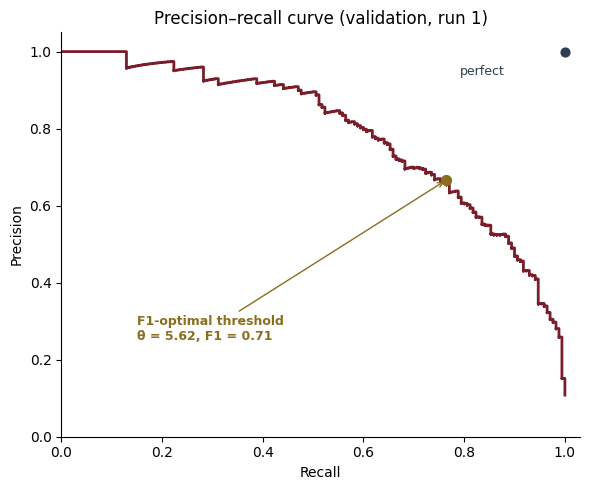

F1-optimal θ: 5.621


In [ ]:
j = 0
train_folds, val_fold, test_fold = make_splits(j)

train_df = master[master["CV_Fold"].isin(train_folds)]
val_df   = master[master["CV_Fold"] == val_fold]

pswm_cv, _ = build_pswm(train_df, background)
val_scores = np.array([score_sequence_fast(s, pswm_cv.values) for s in val_df["sequence"]])

fig, theta = plot_pr_curve(val_df["Label"].values, val_scores,
                           title=f"Precision–recall curve (validation, run {j+1})")
plt.show()
print("F1-optimal θ:", round(theta, 3))